In [1]:
# imports
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

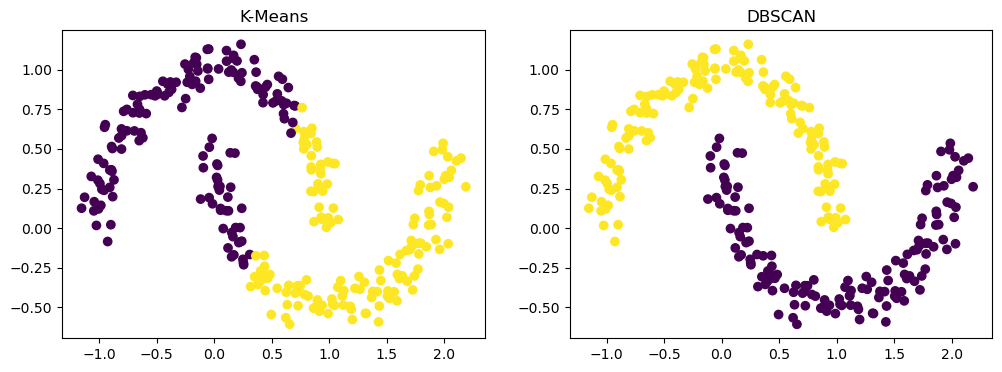

In [2]:
# Before the football data, a toy example: two crescent shaped groups
# K-Means draws a straight line between two centers, can it handle this shape?
moons, _ = make_moons(n_samples=300, noise=0.07, random_state=42)

km_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(moons)
db_labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(moons)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(moons[:, 0], moons[:, 1], c=km_labels, cmap='viridis')
axes[0].set_title('K-Means')
axes[1].scatter(moons[:, 0], moons[:, 1], c=db_labels, cmap='viridis')
axes[1].set_title('DBSCAN')
plt.show()

In [ ]:
# DBSCAN = a point with enough neighbors close by starts a cluster, and the cluster keeps growing through nearby points
# Points that are not close to anyone are labeled -1 (noise) and do not go in any cluster
# eps         = how close counts as a neighbor (distance)
# min_samples = how many points (including itself) must be within eps for a point to be a core point
db_labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(moons)
print("Clusters found:", len(set(db_labels)) - (1 if -1 in db_labels else 0))
print("Noise points:  ", (db_labels == -1).sum())

Clusters found: 2
Noise points:   0


In [ ]:
# import data: same drafted RBs from K-Means
df = pd.read_csv('rb_comps.csv')
df.columns

Index(['draft', 'pick', 'player', 'att', 'yds', 'y_a', 'td', 'fumbles',
       'off_grade', 'run_grade', 'yaco_a', 'mtf', 'lng', '10_plus', 'bay_pct',
       'first', 'tgt', 'rec', 'rec_yds', 'y_rr', 'drp', 'elu',
       'fantasy_finish'],
      dtype='object')

In [5]:
df

,draft,pick,player,att,yds,y_a,td,fumbles,off_grade,run_grade,...,10_plus,bay_pct,first,tgt,rec,rec_yds,y_rr,drp,elu,fantasy_finish
0,2026,3,Jeremiyah Love,199,1372.0,6.9,18,1,93.1,93.7,...,39,52.9,63,34,27,280,1.83,1,127.5,NaN
1,2026,32,Jadarian Price,113,674.0,6.0,11,3,78.6,79.9,...,24,45.0,35,7,6,87,1.23,0,118.6,NaN
2,2026,90,Kaelon Black,186,1034.0,5.6,10,2,83.7,85.5,...,26,40.7,51,7,5,42,0.31,0,58.2,NaN
3,2026,108,Jonah Coleman,157,758.0,4.8,15,2,82.1,83.8,...,20,33.4,55,34,31,346,1.73,0,85.7,NaN
4,2026,122,Mike Washington Jr,167,1066.0,6.4,8,3,78.3,84.3,...,30,48.3,52,36,28,226,0.99,1,73.2,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,2017,121,Joe Williams,210,1389.0,6.6,10,5,65.6,67.1,...,36,48.2,62,13,9,107,0.79,3,54.6,4.0
100,2017,132,Donnel Pumphrey,350,2132.0,6.1,17,2,76.2,75.3,...,59,47.0,96,39,27,236,1.17,3,68.4,4.0
101,2017,134,Jamaal Williams,235,1371.0,5.8,12,2,81.7,80.5,...,34,43.3,65,7,6,74,0.54,0,77.7,2.0
102,2017,140,Wayne Gallman,232,1131.0,4.9,17,2,75.4,77.8,...,28,28.0,61,26,20,143,0.54,1,72.1,3.0


In [6]:
# DBSCAN is unsupervised too, so no y and no train/test split
features = ['pick', 'att', 'yds', 'y_a', 'td', 'off_grade', 'run_grade', 'yaco_a', 'mtf', 'lng',
            '10_plus', 'bay_pct', 'first', 'tgt', 'rec', 'rec_yds', 'y_rr', 'elu']
X = df[features]

In [ ]:
# DBSCAN uses distance (eps) just like KNN and K-Means, so scale first
# Why do we scale when using distance? (think TDs vs Yards)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# eps is the hard part. Too small and everyone is noise, too big and everyone is one cluster
# Try a few values and see what happens (-1 is noise)
for eps in [2, 2.5, 3, 3.25, 3.5, 4]:
    labels = DBSCAN(eps=eps, min_samples=4).fit_predict(X_scaled)
    print(f"eps={eps}:", pd.Series(labels).value_counts().to_dict())

eps=2: {-1: 104}
eps=2.5: {-1: 85, 0: 15, 1: 4}
eps=3: {0: 70, -1: 30, 1: 4}
eps=3.25: {0: 87, -1: 13, 1: 4}
eps=3.5: {0: 100, -1: 4}
eps=4: {0: 100, -1: 4}


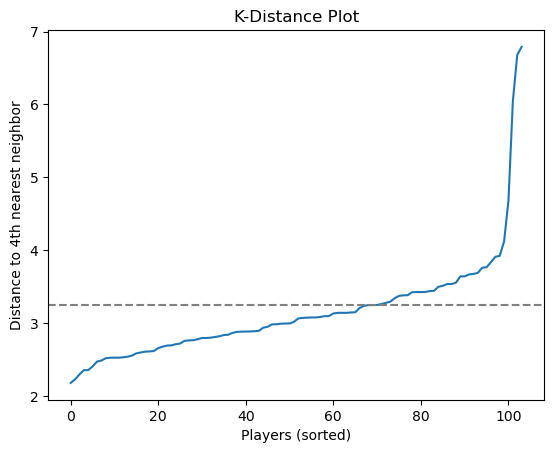

In [9]:
# A smarter way to pick eps: for each player, how far away is their 4th closest neighbor?
# Sort those distances. The "elbow" where the line shoots up is where players start to be far from everyone
neighbors = NearestNeighbors(n_neighbors=4).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.plot(k_dist)
plt.axhline(3.25, color='gray', linestyle='--')
plt.xlabel('Players (sorted)')
plt.ylabel('Distance to 4th nearest neighbor')
plt.title('K-Distance Plot')
plt.show()

In [10]:
# min_samples = 4, eps = 3.25
dbscan = DBSCAN(eps=3.25, min_samples=4)
df['cluster'] = dbscan.fit_predict(X_scaled)

df['cluster'].value_counts().sort_index()

-1    13
 0    87
 1     4
Name: cluster, dtype: int64

In [ ]:
# The big idea: -1 players are the ones DBSCAN says do not look like anybody else
# Do these make sense as unique players? Why would K-Means never show us this?
df[df['cluster'] == -1][['draft', 'player', 'pick', 'yds', 'off_grade']]

,draft,player,pick,yds,off_grade
5,2025,Ashton Jeanty,6,2595.0,94.9
12,2025,Cam Skattebo,105,1712.0,93.3
22,2024,Bucky Irving,125,1192.0,88.2
45,2021,Najee Harris,22,1464.0,89.8
47,2021,Javonte Williams,35,1168.0,94.3
68,2019,Darell Henderson,70,1909.0,88.1
76,2019,Tony Pollard,128,559.0,78.5
88,2018,Chase Edmonds,134,31.0,70.6
90,2017,Christian McCaffrey,8,1590.0,85.0
93,2017,Alvin Kamara,67,596.0,79.9


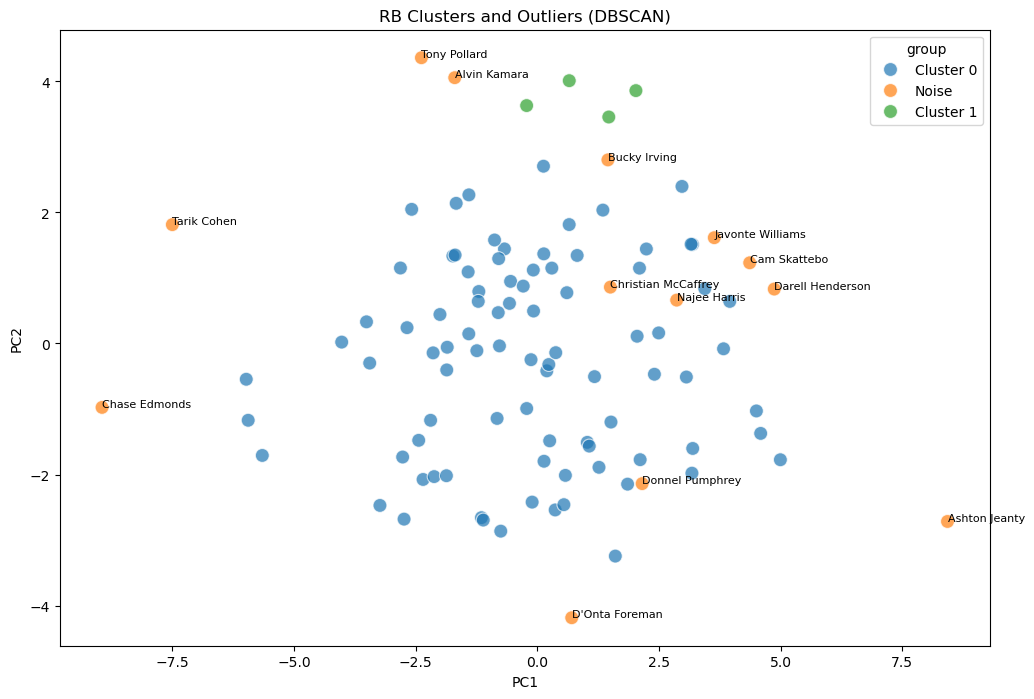

In [ ]:
# squish 18 columns down to 2 with PCA just for the plot just like K-means 
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)
df['PC1'] = components[:, 0]
df['PC2'] = components[:, 1]
df['group'] = df['cluster'].map(lambda x: 'Noise' if x == -1 else f'Cluster {x}')

plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, x='PC1', y='PC2', hue='group', s=100, alpha=0.7, edgecolor='w')

for _, row in df[df['cluster'] == -1].iterrows():
    plt.annotate(row['player'], (row['PC1'], row['PC2']), fontsize=8)

plt.title('RB Clusters and Outliers (DBSCAN)')
plt.show()

In [13]:
# What makes the noise players different from the main group?
means = df.groupby('group')[features].mean().round(1)
means

,pick,att,yds,y_a,td,off_grade,run_grade,yaco_a,mtf,lng,10_plus,bay_pct,first,tgt,rec,rec_yds,y_rr,elu
group,,,,,,,,,,,,,,,,,,
Cluster 0,86.1,203.7,1182.9,5.8,13.1,83.6,85.0,3.6,51.0,65.1,33.2,41.7,60.6,27.6,22.5,200.1,1.1,94.2
Cluster 1,21.2,180.5,1102.0,6.1,12.2,83.8,82.8,3.7,41.8,79.8,28.5,51.4,51.2,54.5,45.8,548.8,2.2,90.6
Noise,80.0,202.3,1312.5,6.0,14.6,83.7,83.1,3.8,58.6,57.3,36.4,42.4,65.9,36.0,28.5,284.2,1.6,119.0
